# Phase 1 — Causal-cone theory check (small-n exact test)

**Question.** At fixed bandwidth, is the concentration of projected-kernel features governed by each qubit's **causal-cone size** (H1) or by **interaction density** (H0)?

**Feature map** (L layers, same input x re-uploaded each layer):

$$U(x)=\prod_{l=1}^{L}\Big[\prod_{(i,j)\in E}e^{-\tfrac{i}{2}c^2x_ix_jZ_iZ_j}\prod_{k}R_y(c\,x_k)\Big],\qquad |\psi(x)\rangle=U(x)|0\rangle^{\otimes n}$$

**Causal cone.** After L layers the reduced state of qubit k depends only on qubits within graph distance L: $C_L(k)=\{j: d_G(k,j)\le L\}$. Section 3 verifies this numerically before it is used.

**Concentration measure.** With $r_k(x)$ the Bloch vector of qubit k, $V=\frac1n\sum_k \operatorname{tr}\operatorname{Cov}_x[r_k(x)]$. Projected kernels compare exactly these vectors, since $\lVert\rho_k(x)-\rho_k(x')\rVert_F^2=\tfrac12\lVert r_k(x)-r_k(x')\rVert^2$; when V shrinks, every pair of inputs looks alike.

**Decision rule.** Criteria A and B are read from the Phase 1 freeze file written before this notebook was run.

| Section | Content | Checkpoint |
|---|---|---|
| 1 | Configuration, freeze verification | Freeze file and input hashes verified |
| 2 | Inputs: Gaussian control + three frozen datasets | Shapes printed |
| 3 | Exact simulator + validation (dense check, light-cone check) | Three PASS lines |
| 4 | Graph families, cone sizes, matched-density pairs | Pair table |
| 5 | Small-n experiment | Results CSV |
| 6 | Criteria A and B, verdict, figures | Verdict printed |

Run `MODE = "smoke"` first (Gaussian inputs only, about 1 minute), then `MODE = "run"`.

## 1. Configuration and freeze verification

In [9]:
from pathlib import Path
import os, json, hashlib, time, itertools, warnings
import numpy as np, pandas as pd
warnings.filterwarnings("ignore", category=FutureWarning)

MODE = "run"#"smoke"             # "smoke" -> Gaussian inputs, small grid | "run" -> frozen grid with all four input sets
ROOT = Path(os.environ.get("PQK_ROOT", Path.cwd() / "pqk-nids"))
PHASE0_MODE = "quick"      # frozen splits come from this Phase 0 run (quick and full splits are identical)
GLOBAL_SEED = 20261001

FREEZE = ROOT / "phase1_freeze" / "phase1_frozen_inputs.json"
RES = ROOT / "results" / "phase1" / MODE; RES.mkdir(parents=True, exist_ok=True)

if MODE == "run":
    assert FREEZE.exists(), f"No freeze file at {FREEZE}. Run freeze_phase1_inputs.py first."
    text = FREEZE.read_text(); digest = hashlib.sha256(text.encode()).hexdigest()
    recorded = (FREEZE.parent / "phase1_frozen_inputs.json.sha256").read_text().split()[0]
    assert digest == recorded, "The freeze file was modified after it was written."
    FZ = json.loads(text)
    def sha(p):
        h = hashlib.sha256()
        with open(p, "rb") as f:
            for b in iter(lambda: f.read(1 << 20), b""): h.update(b)
        return h.hexdigest()
    bad = [k for k, v in FZ["file_sha256"].items() if sha(ROOT / k) != v]
    assert not bad, f"Inputs changed since the freeze: {bad}"
    G = FZ["hypotheses"]["small_n_test"]
    QUBITS, LAYERS, BANDWIDTHS, NSAMP = G["qubits"], G["layers"], G["bandwidths"], G["samples_per_config"]
    print(f"Freeze verified (SHA-256 {digest[:16]}…, created {FZ['created']}); all {len(FZ['file_sha256'])} input files unchanged.")
else:
    FZ = None
    QUBITS, LAYERS, BANDWIDTHS, NSAMP = [6, 8], [1, 2], [0.6], 50
CRIT_A_R2, CRIT_A_P, CRIT_A_SHARE, CRIT_B_SHARE = 0.70, 0.05, 0.75, 0.80   # identical to criteria A and B in the freeze file
print(f"MODE={MODE}  qubits={QUBITS}  layers={LAYERS}  bandwidths={BANDWIDTHS}  samples/config={NSAMP}")
print("CHECKPOINT 1: configuration ready.")

Freeze verified (SHA-256 93ce9a06922e9ab0…, created 2026-10-06 17:55:58 EDT); all 17 input files unchanged.
MODE=run  qubits=[6, 8, 9, 10]  layers=[1, 2, 3]  bandwidths=[0.3, 0.6, 1.0]  samples/config=200
CHECKPOINT 1: configuration ready.


## 2. Inputs

* **Gaussian control**: i.i.d. standard normal features (no data structure at all).
* **Fashion-MNIST**: first n components of the frozen PCA-16 view (standardised on the training split).
* **NF-UNSW-NB15-v2** and **UNSW-NB15**: first n features of the frozen MI-16 view, after the Phase 0 preprocessor.

Each uses the same 200 training rows for every configuration (fixed seed), so configurations differ only in the circuit.

In [10]:
import joblib
def signed_log1p(X):   # needed to unpickle the Phase 0 preprocessors
    return np.sign(X) * np.log1p(np.abs(X))

rng = np.random.default_rng(GLOBAL_SEED)
NMAX = max(QUBITS)
INPUTS = {"gaussian": rng.standard_normal((NSAMP, NMAX))}

if MODE == "run":
    PROC = ROOT / "data" / "processed"; ranks = json.load(open(ROOT / "results" / "phase0" / PHASE0_MODE / "feature_rankings.json"))
    def rows(ds):
        tr = pd.read_parquet(PROC / ds / f"train_{PHASE0_MODE}.parquet")
        idx = np.sort(np.random.default_rng(GLOBAL_SEED).choice(len(tr), NSAMP, replace=False))
        return tr.iloc[idx]
    # Fashion-MNIST PCA-16
    tr = rows("fashion_mnist"); pre = joblib.load(PROC / "fashion_mnist" / f"preprocessor_{PHASE0_MODE}.joblib")
    pcas = joblib.load(PROC / "fashion_mnist" / f"pca_{PHASE0_MODE}.joblib"); pca, sc = pcas[16]
    INPUTS["fashion_mnist"] = sc.transform(pca.transform(pre["ct"].transform(tr[pre["cols"]])))[:, :NMAX]
    # security datasets, MI-16
    for ds in ["nf_unsw_nb15_v2", "unsw_nb15"]:
        tr = rows(ds); pre = joblib.load(PROC / ds / f"preprocessor_{PHASE0_MODE}.joblib")
        X = pre["ct"].transform(tr[pre["cols"]]); names = list(pre["names"])
        cols = [names.index(f) for f in ranks[ds]["mi"][:16]]
        assert ranks[ds]["mi"][:16] == FZ["feature_definitions"][f"{ds}/mi16"], "MI-16 feature list differs from the freeze"
        INPUTS[ds] = np.asarray(X[:, cols], dtype=float)[:, :NMAX]
for k, v in INPUTS.items():
    print(f"{k:18s} shape={v.shape}  mean={v.mean():+.3f}  sd={v.std():.3f}")
print("CHECKPOINT 2: inputs loaded.")

gaussian           shape=(200, 10)  mean=-0.006  sd=1.010
fashion_mnist      shape=(200, 10)  mean=-0.021  sd=0.980
nf_unsw_nb15_v2    shape=(200, 10)  mean=+0.017  sd=0.863
unsw_nb15          shape=(200, 10)  mean=-0.011  sd=0.978
CHECKPOINT 2: inputs loaded.


## 3. Exact simulator and its validation

States are simulated exactly (statevector, batched over inputs). Three checks must pass before any result is trusted:

1. **Dense check**: for n = 3 the batched simulator matches an explicit 8×8 unitary built from Kronecker products.
2. **Normalisation**: every state has unit norm.
3. **Light-cone check**: changing a feature of any qubit *outside* $C_L(k)$ leaves qubit k's Bloch vector unchanged (to 1e-10), while changing features inside the cone does change it. This is the property the whole hypothesis rests on.

In [11]:
def zsigns(n):
    D = 2 ** n
    bits = (np.arange(D)[:, None] >> (n - 1 - np.arange(n))) & 1   # qubit 0 = most significant bit
    return 1 - 2 * bits                                            # (D, n), Z eigenvalues +1/-1

def simulate(X, edges, L, c):
    # X: (N, n) features. Returns (N, 2**n) states U(x)|0...0>.
    N, n = X.shape; D = 2 ** n
    psi = np.zeros((N, D), dtype=complex); psi[:, 0] = 1.0
    if edges:
        s = zsigns(n); S = np.stack([s[:, i] * s[:, j] for i, j in edges], 1)          # (D, E)
        W = np.stack([X[:, i] * X[:, j] for i, j in edges], 1)                         # (N, E)
        phase = np.exp(-0.5j * (c ** 2) * (W @ S.T))                                    # (N, D)
    for _ in range(L):
        for k in range(n):
            th = c * X[:, k]; co = np.cos(th / 2)[:, None, None]; si = np.sin(th / 2)[:, None, None]
            p = psi.reshape(N, 2 ** k, 2, 2 ** (n - k - 1))
            a0 = p[:, :, 0, :].copy(); a1 = p[:, :, 1, :].copy()
            p[:, :, 0, :] = co * a0 - si * a1
            p[:, :, 1, :] = si * a0 + co * a1
        if edges:
            psi = psi * phase
    return psi

def bloch(psi, n):
    N = psi.shape[0]; R = np.empty((N, n, 3))
    for k in range(n):
        p = psi.reshape(N, 2 ** k, 2, 2 ** (n - k - 1)); a0, a1 = p[:, :, 0, :], p[:, :, 1, :]
        r01 = (a0 * a1.conj()).sum((1, 2))
        R[:, k] = np.stack([2 * r01.real, -2 * r01.imag, (abs(a0) ** 2).sum((1, 2)) - (abs(a1) ** 2).sum((1, 2))], 1)
    return R

def dense_state(x, edges, L, c):
    n = len(x); I = np.eye(2)
    def on(k, g):
        out = np.array([[1.0]])
        for q in range(n): out = np.kron(out, g if q == k else I)
        return out
    U = np.eye(2 ** n, dtype=complex)
    for _ in range(L):
        for k in range(n):
            t = c * x[k]; U = on(k, np.array([[np.cos(t / 2), -np.sin(t / 2)], [np.sin(t / 2), np.cos(t / 2)]])) @ U
        for i, j in edges:
            ZZ = on(i, np.diag([1., -1.])) @ on(j, np.diag([1., -1.]))
            U = (np.cos(c ** 2 * x[i] * x[j] / 2) * np.eye(2 ** n) - 1j * np.sin(c ** 2 * x[i] * x[j] / 2) * ZZ) @ U
    v = np.zeros(2 ** n, dtype=complex); v[0] = 1; return U @ v

CHECKS = {}
t = np.random.default_rng(1).standard_normal((5, 3)); e3 = [(0, 1), (1, 2), (0, 2)]
d = max(np.abs(simulate(t, e3, 2, 0.8)[i] - dense_state(t[i], e3, 2, 0.8)).max() for i in range(5))
CHECKS["dense_check_n3"] = dict(max_abs_diff=float(d), pass_=bool(d < 1e-12))
print("dense check done")

dense check done


### Graph families and causal cones
Graphs are built for each n; cone sizes come from breadth-first search. These are needed by the light-cone check below and by Section 4.

In [12]:
import networkx as nx

def families(n, seed=GLOBAL_SEED):
    F = {"empty": [], "chain": [(i, i + 1) for i in range(n - 1)], "ring": [(i, (i + 1) % n) for i in range(n)],
         "star": [(0, i) for i in range(1, n)],
         "complete": [(i, j) for i in range(n) for j in range(i + 1, n)]}
    if n % 2 == 0:
        F["matching"] = [(i, i + 1) for i in range(0, n, 2)]
    def cycles(sizes):
        e, s0 = [], 0
        for m in sizes:
            e += [(s0 + i, s0 + (i + 1) % m) for i in range(m)]; s0 += m
        return e
    if n % 3 == 0: F["triangles"] = cycles([3] * (n // 3))
    if n >= 8: F["two_cycles"] = cycles([n // 2, n - n // 2])
    if n % 4 == 0: F["k4s"] = sum(([(b + i, b + j) for i in range(4) for j in range(i + 1, 4)] for b in range(0, n, 4)), [])
    if n % 2 == 0 and n >= 6:
        for s in range(seed, seed + 200):
            g = nx.random_regular_graph(3, n, seed=s)
            if nx.is_connected(g): F["regular3"] = sorted(tuple(sorted(e)) for e in g.edges()); break
    return F

def cone_sizes(n, edges, L):
    g = nx.Graph(); g.add_nodes_from(range(n)); g.add_edges_from(edges)
    return np.array([sum(1 for d in nx.single_source_shortest_path_length(g, k, cutoff=L).values()) for k in range(n)])

def cone_members(n, edges, L, k):
    g = nx.Graph(); g.add_nodes_from(range(n)); g.add_edges_from(edges)
    return set(nx.single_source_shortest_path_length(g, k, cutoff=L))

# light-cone check: n = 8, every family, L = 1, 2, 3, every qubit
rng = np.random.default_rng(2); x = rng.standard_normal((1, 8)); worst_out, inside_moves, tested = 0.0, 0, 0
norm_err = 0.0
for name, E in families(8).items():
    for L in [1, 2, 3]:
        base = simulate(x, E, L, 0.8); norm_err = max(norm_err, abs(np.linalg.norm(base) - 1)); R0 = bloch(base, 8)
        for k in range(8):
            cone = cone_members(8, E, L, k)
            for j in range(8):
                xp = x.copy(); xp[0, j] += 0.7
                dk = np.abs(bloch(simulate(xp, E, L, 0.8), 8)[0, k] - R0[0, k]).max()
                if j in cone:
                    inside_moves += dk > 1e-6; tested += 1
                else:
                    worst_out = max(worst_out, dk)
CHECKS["normalisation"] = dict(max_norm_error=float(norm_err), pass_=bool(norm_err < 1e-12))
CHECKS["light_cone_outside_has_no_effect"] = dict(max_change_from_outside=float(worst_out), inside_perturbations_that_changed_state=f"{inside_moves}/{tested}",
                                                  pass_=bool(worst_out < 1e-10 and inside_moves / tested > 0.9))
for k, v in CHECKS.items():
    print(f"{'PASS' if v['pass_'] else 'FAIL'}  {k}  {({a: b for a, b in v.items() if a != 'pass_'})}")
json.dump(CHECKS, open(RES / "simulator_checks.json", "w"), indent=2, default=str)
assert all(v["pass_"] for v in CHECKS.values()), "Simulator validation failed: stop here."
print("CHECKPOINT 3: simulator and light-cone property verified.")

PASS  dense_check_n3  {'max_abs_diff': 1.1443916996305594e-16}
PASS  normalisation  {'max_norm_error': 8.881784197001252e-16}
PASS  light_cone_outside_has_no_effect  {'max_change_from_outside': 1.1102230246251565e-15, 'inside_perturbations_that_changed_state': '965/974'}
CHECKPOINT 3: simulator and light-cone property verified.


## 4. Cone sizes and matched-density pairs

For every n, layer count L and graph family: edge count, density $|E|/\binom{n}{2}$, and mean cone size $\bar m=\frac1n\sum_k|C_L(k)|$. A **matched pair** is two graphs with the same n and the same edge count (so identical density) whose mean cone sizes differ by at least 0.5 at the same L. These pairs separate the two hypotheses: density cannot tell them apart, the cone can.

In [13]:
G_ROWS = []
for n in QUBITS:
    for name, E in families(n).items():
        for L in LAYERS:
            cs = cone_sizes(n, E, L)
            G_ROWS.append(dict(n=n, graph=name, L=L, edges=len(E), density=round(len(E) / (n * (n - 1) / 2), 4),
                               mean_cone=float(cs.mean()), max_cone=int(cs.max()), degree_seq=str(sorted(dict(nx.Graph(E).degree()).values()) if E else [0] * n)))
GT = pd.DataFrame(G_ROWS); GT.to_csv(RES / "graphs.csv", index=False)
P_ROWS = []
for (n, L, e), grp in GT.groupby(["n", "L", "edges"]):
    for a, b in itertools.combinations(grp.itertuples(), 2):
        if abs(a.mean_cone - b.mean_cone) >= 0.5:
            P_ROWS.append(dict(n=n, L=L, edges=e, density=a.density, graph_small_cone=a.graph if a.mean_cone < b.mean_cone else b.graph,
                               graph_large_cone=b.graph if a.mean_cone < b.mean_cone else a.graph,
                               cone_small=min(a.mean_cone, b.mean_cone), cone_large=max(a.mean_cone, b.mean_cone),
                               same_degree_sequence=a.degree_seq == b.degree_seq))
PAIRS = pd.DataFrame(P_ROWS); PAIRS.to_csv(RES / "matched_pairs.csv", index=False)
print(GT[GT.L == max(LAYERS)].drop(columns="degree_seq").to_string(index=False))
print(f"\n{len(PAIRS)} matched-density pairs (equal n, equal edge count, cone difference >= 0.5):")
print(PAIRS.to_string(index=False))
assert len(PAIRS) > 0, "No matched pairs found: the test cannot discriminate."
print("CHECKPOINT 4: graphs and matched pairs saved.")

 n      graph  L  edges  density  mean_cone  max_cone
 6      empty  3      0   0.0000   1.000000         1
 6      chain  3      5   0.3333   5.000000         6
 6       ring  3      6   0.4000   6.000000         6
 6       star  3      5   0.3333   6.000000         6
 6   complete  3     15   1.0000   6.000000         6
 6   matching  3      3   0.2000   2.000000         2
 6  triangles  3      6   0.4000   3.000000         3
 6   regular3  3      9   0.6000   6.000000         6
 8      empty  3      0   0.0000   1.000000         1
 8      chain  3      7   0.2500   5.500000         7
 8       ring  3      8   0.2857   7.000000         7
 8       star  3      7   0.2500   8.000000         8
 8   complete  3     28   1.0000   8.000000         8
 8   matching  3      4   0.1429   2.000000         2
 8 two_cycles  3      8   0.2857   4.000000         4
 8        k4s  3     12   0.4286   4.000000         4
 8   regular3  3     12   0.4286   8.000000         8
 9      empty  3      0   0.

## 5. Small-n experiment

For every input set, bandwidth c, qubit count n, graph and L: simulate all 200 inputs, compute Bloch vectors, and record
* **V**, the concentration measure (lower = more concentrated);
* the mean pairwise projected distance $\bar D=\frac{1}{n}\,\mathbb E_{x\ne x'}\sum_k\lVert\rho_k(x)-\rho_k(x')\rVert_F^2$;
* the variance of the projected kernel $k(x,x')=\exp(-\gamma\sum_k\lVert\rho_k(x)-\rho_k(x')\rVert_F^2)$ at $\gamma=1$, for reference.

In [14]:
rows, t0 = [], time.time()
for src, Xall in INPUTS.items():
    for c in BANDWIDTHS:
        for n in QUBITS:
            X = Xall[:, :n]
            for name, E in families(n).items():
                for L in LAYERS:
                    R = bloch(simulate(X, E, L, c), n)                                  # (N, n, 3)
                    V = float(np.mean([np.trace(np.cov(R[:, k].T)) for k in range(n)]))
                    diff = R[:, None, :, :] - R[None, :, :, :]
                    dist = 0.5 * (diff ** 2).sum((2, 3))                                # sum_k ||rho_k - rho_k'||_F^2
                    iu = np.triu_indices(len(X), 1); d = dist[iu]
                    rows.append(dict(inputs=src, c=c, n=n, graph=name, L=L, edges=len(E), density=len(E) / (n * (n - 1) / 2),
                                     mean_cone=float(cone_sizes(n, E, L).mean()), V=V, D_mean=float(d.mean() / n),
                                     kernel_var_gamma1=float(np.exp(-d).var())))
    print(f"  {src}: done ({time.time() - t0:.0f}s)")
RS = pd.DataFrame(rows); RS.to_csv(RES / "smalln_results.csv", index=False)
print(f"{len(RS)} configurations simulated.")
print("CHECKPOINT 5: results saved ->", RES / "smalln_results.csv")

  gaussian: done (3s)
  fashion_mnist: done (6s)
  nf_unsw_nb15_v2: done (9s)
  unsw_nb15: done (12s)
1152 configurations simulated.
CHECKPOINT 5: results saved -> /Users/aakarshetar/Documents/Q-kernel/Phase 0/pqk-nids/results/phase1/run/smalln_results.csv


## 6. Criteria A and B, verdict and figures

* **Criterion A** (per input set × bandwidth cell): $R^2$ of $\log V$ on mean cone size ≥ 0.70, *and* adding density to that model is not significant (partial F-test, p > 0.05). Passed overall if ≥ 75% of cells pass.
* **Criterion B**: across all matched pairs (equal n, equal edge count, same L, same bandwidth, same inputs), the graph with the larger cone has the lower V in ≥ 80% of comparisons.
* **Verdict**: H1 supported if A and B both pass; rejected if both fail; otherwise mixed. All three outcomes are reported as they are.

In [15]:
from scipy import stats

def ols(y, X):
    X1 = np.column_stack([np.ones(len(y)), X]); b, *_ = np.linalg.lstsq(X1, y, rcond=None)
    rss = float(((y - X1 @ b) ** 2).sum()); tss = float(((y - y.mean()) ** 2).sum()); return rss, 1 - rss / tss, X1.shape[1]

A_rows = []
for (src, c), g in RS.groupby(["inputs", "c"]):
    y = np.log(g.V.to_numpy()); cone = g.mean_cone.to_numpy(); dens = g.density.to_numpy()
    rss_c, r2_c, p_c = ols(y, cone); rss_d, r2_d, _ = ols(y, dens); rss_f, r2_f, p_f = ols(y, np.column_stack([cone, dens]))
    F = ((rss_c - rss_f) / (p_f - p_c)) / (rss_f / (len(y) - p_f)); pval = float(stats.f.sf(F, p_f - p_c, len(y) - p_f))
    A_rows.append(dict(inputs=src, c=c, configs=len(g), r2_cone=round(r2_c, 3), r2_density=round(r2_d, 3), r2_both=round(r2_f, 3),
                       partial_F_add_density=round(F, 3), p_add_density=round(pval, 4),
                       cell_pass=bool(r2_c >= CRIT_A_R2 and pval > CRIT_A_P)))
A = pd.DataFrame(A_rows); A.to_csv(RES / "criterion_A.csv", index=False)

B_rows = []
key = RS.set_index(["inputs", "c", "n", "L", "graph"]).V
for p in PAIRS.itertuples():
    for src in INPUTS:
        for c in BANDWIDTHS:
            vs, vl = key[(src, c, p.n, p.L, p.graph_small_cone)], key[(src, c, p.n, p.L, p.graph_large_cone)]
            B_rows.append(dict(inputs=src, c=c, n=p.n, L=p.L, edges=p.edges, small=p.graph_small_cone, large=p.graph_large_cone,
                               V_small_cone=vs, V_large_cone=vl, larger_cone_more_concentrated=bool(vl < vs),
                               same_degree_sequence=p.same_degree_sequence))
B = pd.DataFrame(B_rows); B.to_csv(RES / "criterion_B.csv", index=False)

a_share = float(A.cell_pass.mean()); b_share = float(B.larger_cone_more_concentrated.mean())
A_pass, B_pass = a_share >= CRIT_A_SHARE, b_share >= CRIT_B_SHARE
verdict = "H1 SUPPORTED" if (A_pass and B_pass) else ("H1 REJECTED" if not (A_pass or B_pass) else "MIXED")
summary = dict(mode=MODE, criterion_A_cells_passing=f"{int(A.cell_pass.sum())}/{len(A)} ({a_share:.0%})", criterion_A_pass=A_pass,
               criterion_B_pairs_consistent=f"{int(B.larger_cone_more_concentrated.sum())}/{len(B)} ({b_share:.0%})", criterion_B_pass=B_pass,
               criterion_B_same_degree_pairs=f"{int(B[B.same_degree_sequence].larger_cone_more_concentrated.sum())}/{int(B.same_degree_sequence.sum())}",
               verdict=verdict)
json.dump(summary, open(RES / "verdict.json", "w"), indent=2)
print(A.to_string(index=False))
print("\nCriterion B by input set:\n", B.groupby("inputs").larger_cone_more_concentrated.agg(["sum", "count", "mean"]).round(3).to_string())
print("\n" + "=" * 70); print(json.dumps(summary, indent=1))
if MODE == "smoke":
    print("Smoke mode uses Gaussian inputs and a reduced grid: the verdict only proves the code runs.")

         inputs   c  configs  r2_cone  r2_density  r2_both  partial_F_add_density  p_add_density  cell_pass
  fashion_mnist 0.3       96    0.078       0.004    0.178                 11.425         0.0011      False
  fashion_mnist 0.6       96    0.001       0.170    0.274                 35.078         0.0000      False
  fashion_mnist 1.0       96    0.368       0.771    0.773                166.316         0.0000      False
       gaussian 0.3       96    0.080       0.003    0.183                 11.693         0.0009      False
       gaussian 0.6       96    0.003       0.216    0.320                 43.227         0.0000      False
       gaussian 1.0       96    0.350       0.776    0.777                177.840         0.0000      False
nf_unsw_nb15_v2 0.3       96    0.041       0.031    0.209                 19.649         0.0000      False
nf_unsw_nb15_v2 0.6       96    0.022       0.107    0.334                 43.665         0.0000      False
nf_unsw_nb15_v2 1.0       96

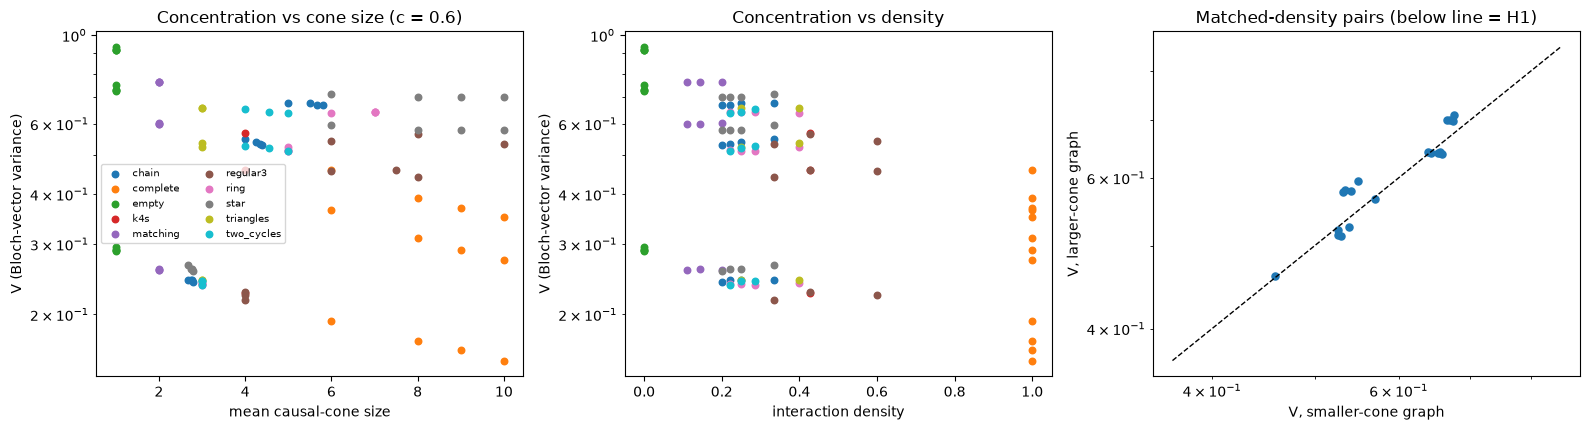

CHECKPOINT 6: verdict and figure saved -> /Users/aakarshetar/Documents/Q-kernel/Phase 0/pqk-nids/results/phase1/run


In [16]:
try:
    import matplotlib.pyplot as plt
    show = RS[RS.inputs == ("fashion_mnist" if "fashion_mnist" in INPUTS else "gaussian")]
    c_mid = sorted(BANDWIDTHS)[len(BANDWIDTHS) // 2]; show = show[show.c == c_mid]
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
    for name, g in show.groupby("graph"):
        ax[0].scatter(g.mean_cone, g.V, s=22, label=name); ax[1].scatter(g.density, g.V, s=22, label=name)
    for a_, xl in zip(ax[:2], ["mean causal-cone size", "interaction density"]):
        a_.set_yscale("log"); a_.set_xlabel(xl); a_.set_ylabel("V (Bloch-vector variance)")
    ax[0].set_title(f"Concentration vs cone size (c = {c_mid})"); ax[1].set_title("Concentration vs density")
    ax[0].legend(fontsize=7, ncol=2)
    bb = B[(B.inputs == show.inputs.iloc[0]) & (B.c == c_mid)]
    ax[2].scatter(bb.V_small_cone, bb.V_large_cone, s=26)
    lim = [min(bb.V_small_cone.min(), bb.V_large_cone.min()) * 0.8, max(bb.V_small_cone.max(), bb.V_large_cone.max()) * 1.2]
    ax[2].plot(lim, lim, "k--", lw=1); ax[2].set_xscale("log"); ax[2].set_yscale("log")
    ax[2].set_xlabel("V, smaller-cone graph"); ax[2].set_ylabel("V, larger-cone graph"); ax[2].set_title("Matched-density pairs (below line = H1)")
    plt.tight_layout(); plt.savefig(RES / "phase1_smalln_figure.png", dpi=160); plt.show()
except ImportError:
    print("matplotlib not installed: figure skipped")
print("CHECKPOINT 6: verdict and figure saved ->", RES)

## What to send back

Zip `results/phase1/run/` (all files: `simulator_checks.json`, `graphs.csv`, `matched_pairs.csv`, `smalln_results.csv`, `criterion_A.csv`, `criterion_B.csv`, `verdict.json`, `phase1_smalln_figure.png`) and the executed notebook.